# 07 · Las medias lunas (Figura 1)

Un problema de juguete en 2 dimensiones para ver el mecanismo "a ojo" antes de los resultados. Entrenamos los cuatro modelos sobre dos medias lunas y dibujamos, sobre toda la región, la probabilidad de clase que predice cada uno (fila de arriba) y cuánta incertidumbre expresa (fila de abajo).

- **Lee:** nada externo (los datos se generan con `make_moons`). Usa `redes.py`.
- **Guarda:** `outputs/F1_medias_lunas.pdf/.png`, que es la Figura 1 del informe.
- **Ojo:** acá las clases son de juguete (no hay morosos); el problema no entra en ningún número del trabajo, solo ilustra la idea.

Spearman incertidumbre vs distancia a los datos: {'XGBoost': np.float64(0.07), 'GP': np.float64(0.91), 'SNGP': np.float64(0.78), 'Ensamble': np.float64(0.76)}


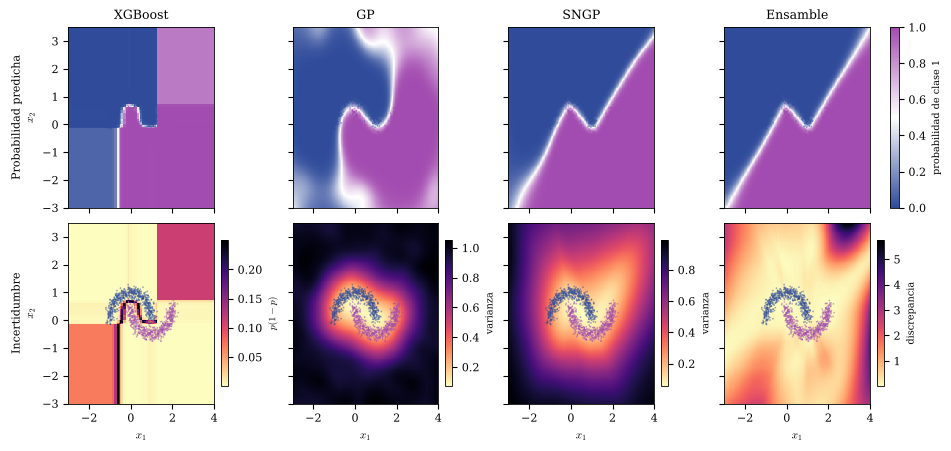

In [1]:
# Qué esperamos ver: donde hay datos, todos los modelos están seguros; lejos de los datos, XGBoost sigue dando
# probabilidades confiadas (no tiene forma de decir "acá no sé"), mientras que el GP, la SNGP y el ensamble suben su
# incertidumbre.
#   - XGBoost: da solo una probabilidad p. Como "incertidumbre" usamos p(1-p), que es alta únicamente cerca de la
#     frontera entre clases, no lejos de los datos.
#   - GP: random Fourier features directo sobre las 2 variables; su varianza crece con la distancia.
#   - SNGP: la misma idea, pero con una red adelante que aprende la forma de las lunas.
#   - Ensamble: 5 SNGP con semillas distintas; su incertidumbre es la discrepancia, o sea la varianza de los 5 logits
#     (si las redes coinciden es chica; si cada una extrapola a su manera, es grande).
# Al final medimos con Spearman cuánto acompaña la incertidumbre de cada modelo a la distancia al dato más cercano.
# La figura está inspirada en la Figura 1 de Liu et al. (2023); el dibujo es nuestro.
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_moons
from scipy.stats import spearmanr
from xgboost import XGBClassifier

from redes import SNGP, GPVariables, entrenar, ajustar_covarianza, predecir

SEED = 0
torch.manual_seed(SEED)                                         # azar reproducible

# 1500 puntos en forma de dos medias lunas; noise = dispersión alrededor de cada luna
X, y = make_moons(n_samples=1500, noise=0.12, random_state=SEED)
X, y = X.astype(np.float32), y.astype(np.float32)              # torch trabaja con float32
idx = np.random.default_rng(SEED).permutation(len(X))           # posiciones mezcladas al azar
n_tr = int(0.8 * len(X))
i_tr, i_va = idx[:n_tr], idx[n_tr:]                             # 80% train, 20% validación

ds_tr = TensorDataset(torch.from_numpy(X[i_tr]), torch.from_numpy(y[i_tr]))   # pares (x, y) de train como tensores
tr = DataLoader(ds_tr, batch_size=64, shuffle=True)             # tandas de 64 (hay pocos datos), mezcladas
va = DataLoader(TensorDataset(torch.from_numpy(X[i_va]), torch.from_numpy(y[i_va])), batch_size=512)   # para el early stopping
cov = DataLoader(ds_tr, batch_size=512)                         # para ajustar la covarianza del GP

# Grilla de 200 x 200 puntos que cubre toda la región a dibujar
# linspace(-3, 4, 200): 200 valores parejos entre -3 y 4; meshgrid arma todas las combinaciones (x1, x2)
gx, gy = np.meshgrid(np.linspace(-3, 4, 200), np.linspace(-3, 3.5, 200))
G = np.c_[gx.ravel(), gy.ravel()].astype(np.float32)            # 40.000 puntos de la grilla, 2 columnas
# Distancia de cada punto de la grilla al dato más cercano (X[::5]: uno de cada 5 datos, para que no tarde)
dist = np.min(np.linalg.norm(G[:, None, :] - X[None, ::5, :], axis=2), axis=1)   # distancia de cada punto a los datos

# XGBoost: solo probabilidad. Como "incertidumbre" usamos p(1-p), que es
# alta únicamente cerca de la frontera, no lejos de los datos.
# n_estimators: cantidad de árboles; max_depth: profundidad de cada uno; learning_rate: cuánto corrige cada árbol
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, random_state=SEED)
xgb.fit(X[i_tr], y[i_tr])
p_xgb = xgb.predict_proba(G)[:, 1]                              # prob. de clase 1 en cada punto de la grilla
u_xgb = p_xgb * (1 - p_xgb)

# GP: random Fourier features directo sobre las 2 variables.
# scale = escala de distancias del kernel (menor = el GP "olvida" más rápido al alejarse).
torch.manual_seed(SEED)
gp = GPVariables(d_in=2, scale=1.0)                             # GP directo sobre x1 y x2
entrenar(gp, tr, va, lr=3e-3, max_epocas=100, paciencia=10, verbose=False)   # lr = paso; paciencia = épocas sin mejorar antes de cortar
ajustar_covarianza(gp, cov)                                     # la "memoria" de dónde hubo datos
lg, u_gp = predecir(gp, torch.from_numpy(G))                    # logit y varianza en cada punto de la grilla
p_gp = 1 / (1 + np.exp(-lg))                                    # sigmoide: de logit a probabilidad

# SNGP: red con norma espectral + capa GP. scale = 3.0 (ver nota abajo).
torch.manual_seed(SEED)
# d_in=2 variables; d_oculta=128 de ancho; n_bloques=2 bloques residuales; coef=0.9 cuánto corrige cada bloque
sngp = SNGP(d_in=2, d_oculta=128, n_bloques=2, coef=0.9, scale=3.0)
entrenar(sngp, tr, va, lr=3e-3, max_epocas=100, paciencia=10, verbose=False)
ajustar_covarianza(sngp, cov)
lg, u_sngp = predecir(sngp, torch.from_numpy(G))
p_sngp = 1 / (1 + np.exp(-lg))
# Ensamble: 5 SNGP iguales a la anterior pero con semillas distintas (cambian los pesos iniciales, las random
# features y el orden de las tandas). Probabilidad = sigmoide del promedio de los 5 logits; incertidumbre =
# discrepancia, o sea la varianza de los 5 logits en cada punto (si las redes coinciden es chica, si no, grande).
logits = []                                                     # acá va el logit de cada red en la grilla
for k in range(5):
    torch.manual_seed(1000 + k)                                 # semilla distinta por red (las mismas que en el 08)
    gen = torch.Generator().manual_seed(1000 + k)               # orden de las tandas distinto por red
    tr_k = DataLoader(ds_tr, batch_size=64, shuffle=True, generator=gen)
    red_k = SNGP(d_in=2, d_oculta=128, n_bloques=2, coef=0.9, scale=3.0)
    entrenar(red_k, tr_k, va, lr=3e-3, max_epocas=100, paciencia=10, verbose=False)
    ajustar_covarianza(red_k, cov)
    logits.append(predecir(red_k, torch.from_numpy(G))[0])      # [0] = el logit (la varianza GP no la usamos acá)
logits = np.array(logits)                                       # forma [5, puntos de la grilla]
p_ens = 1 / (1 + np.exp(-logits.mean(0)))                       # mean(0): promedio de las 5 redes en cada punto
u_ens = logits.var(0)                                           # var(0): discrepancia entre las 5 redes
# Nota: las dos escalas (1.0 y 3.0) se eligieron mirando la pérdida de validación
# y el mapa; es un problema de juguete y no entra en ningún resultado del trabajo.

print("Spearman incertidumbre vs distancia a los datos:",
      {"XGBoost": round(spearmanr(dist, u_xgb)[0], 2), "GP": round(spearmanr(dist, u_gp)[0], 2),
       "SNGP": round(spearmanr(dist, u_sngp)[0], 2), "Ensamble": round(spearmanr(dist, u_ens)[0], 2)})

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 8,
                     "axes.titlesize": 9, "axes.labelsize": 8, "axes.linewidth": 0.6})
cmap_clases = LinearSegmentedColormap.from_list("clases", ["#2F4B9A", "#FFFFFF", "#A24BB0"])  # azul - blanco - violeta
modelos = [("XGBoost", p_xgb, u_xgb, r"$p(1-p)$"), ("GP", p_gp, u_gp, "varianza"),
           ("SNGP", p_sngp, u_sngp, "varianza"), ("Ensamble", p_ens, u_ens, "discrepancia")]
colores_pts = np.where(y[i_tr] == 1, "#A24BB0", "#2F4B9A")

fig, ejes = plt.subplots(2, 4, figsize=(9.4, 4.4), sharex=True, sharey=True, layout="constrained")  # constrained: acomoda barras de color sin pisarse
for j, (nombre, p, u, etiqueta) in enumerate(modelos):
    m1 = ejes[0, j].pcolormesh(gx, gy, p.reshape(gx.shape), cmap=cmap_clases, vmin=0, vmax=1,
                               shading="auto", rasterized=True)
    ejes[0, j].set_title(nombre)
    m2 = ejes[1, j].pcolormesh(gx, gy, u.reshape(gx.shape), cmap="magma_r", shading="auto", rasterized=True)
    fig.colorbar(m2, ax=ejes[1, j], fraction=0.05, pad=0.02).set_label(etiqueta, fontsize=7)
    for ax in ejes[:, j]:                                       # puntos de entrenamiento encima
        ax.scatter(X[i_tr, 0], X[i_tr, 1], c=colores_pts, s=1.5, alpha=0.5, linewidths=0)
        ax.set_xlim(-3, 4); ax.set_ylim(-3, 3.5)
    ejes[1, j].set_xlabel("$x_1$")
fig.colorbar(m1, ax=ejes[0, :], fraction=0.03, pad=0.02).set_label("probabilidad de clase 1", fontsize=7)
ejes[0, 0].set_ylabel("Probabilidad predicha\n$x_2$")
ejes[1, 0].set_ylabel("Incertidumbre\n$x_2$")
os.makedirs("outputs", exist_ok=True)
fig.savefig("outputs/F1_medias_lunas.pdf", bbox_inches="tight")
fig.savefig("outputs/F1_medias_lunas.png", dpi=300, bbox_inches="tight")
plt.show()

# Spearman entre incertidumbre y distancia a los datos: XGBoost 0.07, GP 0.91, SNGP 0.78, ensamble 0.76. La "duda" de
# XGBoost no tiene nada que ver con estar lejos (solo aparece en la frontera entre clases); la del GP, la SNGP y el
# ensamble sí crece al alejarse de las lunas. La discrepancia del ensamble es más "manchada": las 5 redes coinciden
# en algunas zonas lejanas y discrepan mucho en otras (arriba a la derecha), porque cada una extrapola a su manera.
# Es exactamente el mecanismo que después buscamos en Home Credit (y que es el pie de la Figura 1).